# Experiment 8: Particle Swarm Optimization (PSO)
**Aim:** To implement a simple Particle Swarm Optimization algorithm for solving an optimization problem using Python.

**Theory:** Each particle has a position **x** and velocity **v**. It is pulled towards its own best position (*pbest*) and the swarm's best position (*gbest*):

v ← w·v + c₁·r₁·(pbest − x) + c₂·r₂·(gbest − x),  x ← x + v

**Problem:** Minimise the 2-D Rastrigin function (global minimum 0 at (0, 0)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)

def rastrigin(x):
    return 10 * len(x) + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x))

def pso(func, dim=2, n_particles=30, iters=100, bounds=(-5.12, 5.12), w=0.7, c1=1.5, c2=1.5):
    lo, hi = bounds
    x = np.random.uniform(lo, hi, (n_particles, dim))
    v = np.random.uniform(-(hi - lo) * 0.1, (hi - lo) * 0.1, (n_particles, dim))
    pbest = x.copy()
    pbest_val = np.array([func(p) for p in x])
    g = pbest[pbest_val.argmin()].copy()
    g_val = pbest_val.min()
    history, snapshots = [g_val], {0: x.copy()}
    for t in range(1, iters + 1):
        r1, r2 = np.random.rand(n_particles, dim), np.random.rand(n_particles, dim)
        v = w * v + c1 * r1 * (pbest - x) + c2 * r2 * (g - x)
        x = np.clip(x + v, lo, hi)
        vals = np.array([func(p) for p in x])
        improved = vals < pbest_val
        pbest[improved], pbest_val[improved] = x[improved], vals[improved]
        if pbest_val.min() < g_val:
            g_val = pbest_val.min(); g = pbest[pbest_val.argmin()].copy()
        history.append(g_val)
        if t in (10, 30, iters): snapshots[t] = x.copy()
    return g, g_val, history, snapshots

best_pos, best_val, hist, snaps = pso(rastrigin)
print("Best position:", np.round(best_pos, 5))
print("Best value   :", round(best_val, 6))

Best position: [-0. -0.]
Best value   : 0.0


## Convergence curve

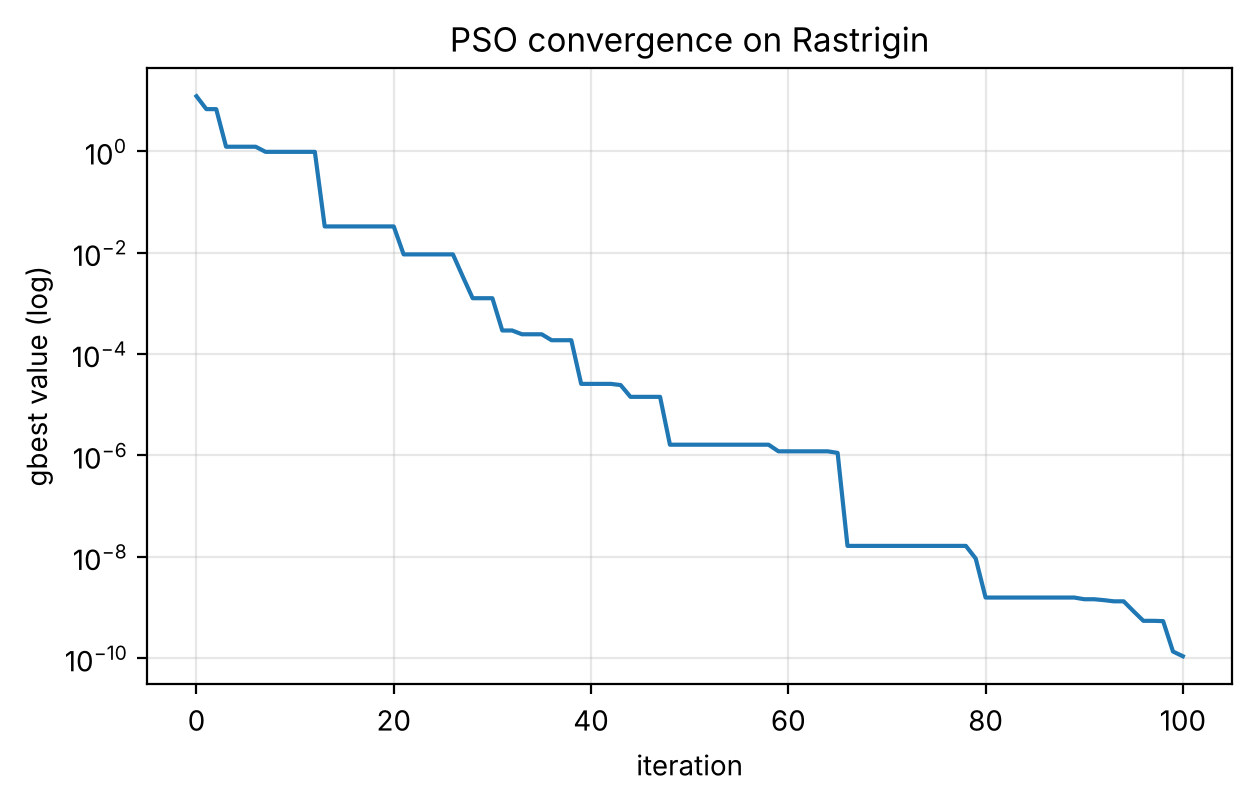

In [2]:
plt.figure(figsize=(7, 4))
plt.plot(hist); plt.yscale("log")
plt.xlabel("iteration"); plt.ylabel("gbest value (log)")
plt.title("PSO convergence on Rastrigin"); plt.grid(alpha=0.3); plt.show()

## Swarm movement over iterations

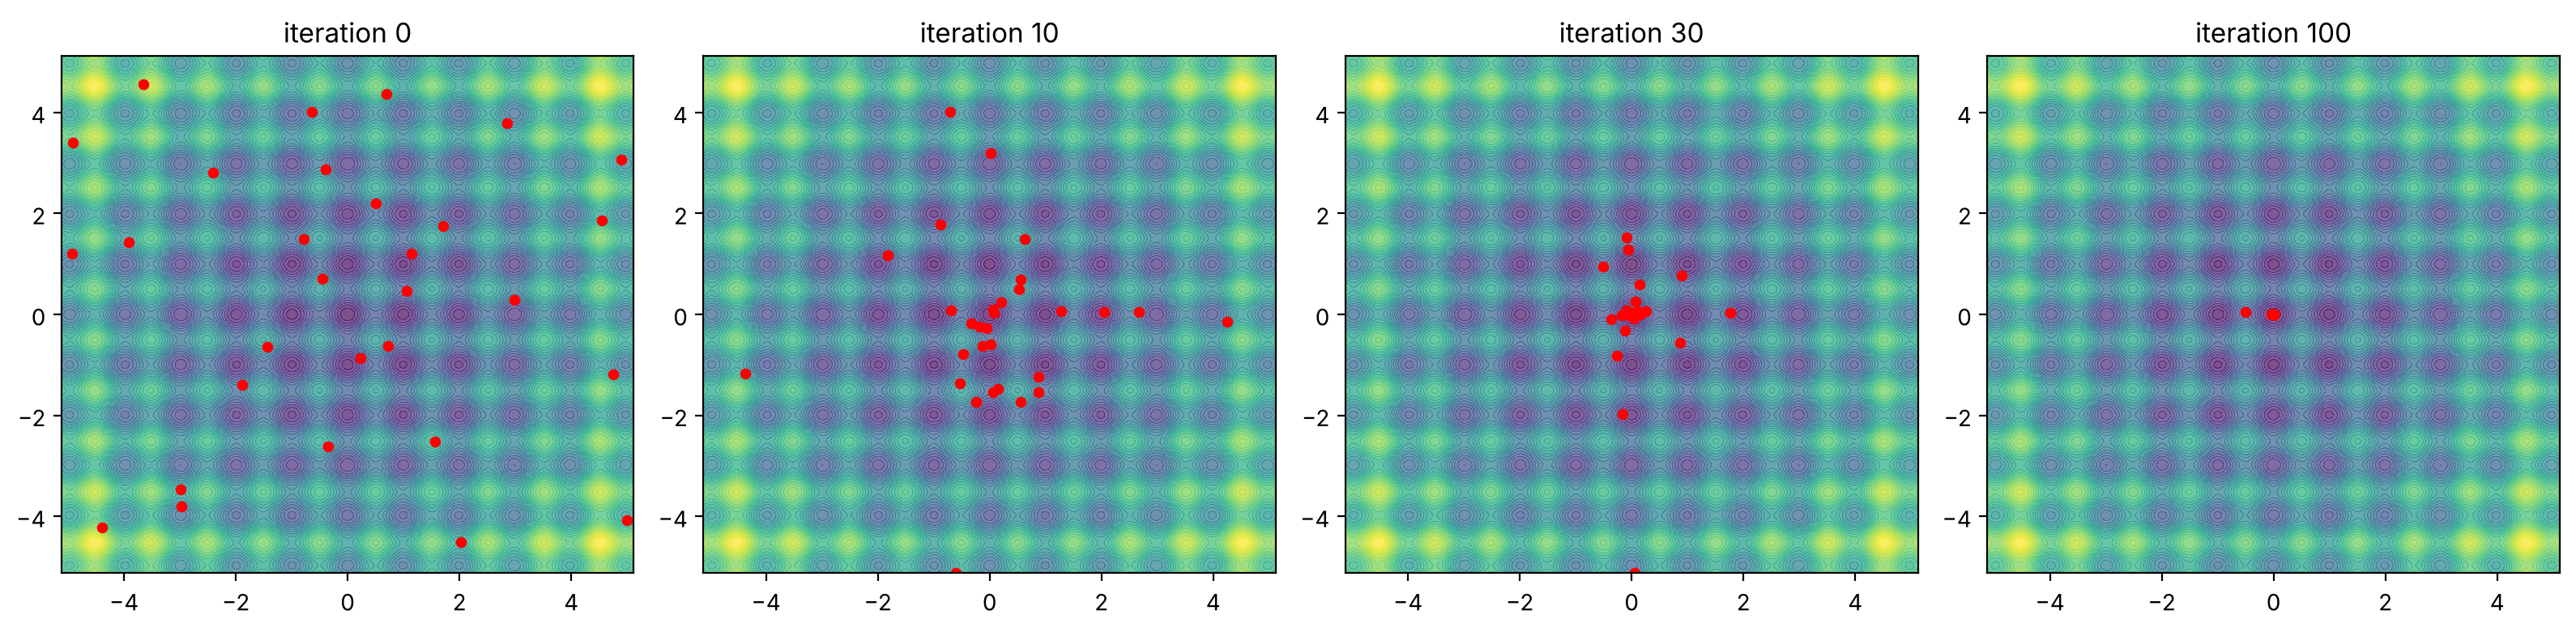

In [3]:
X, Y = np.meshgrid(np.linspace(-5.12, 5.12, 300), np.linspace(-5.12, 5.12, 300))
Z = 20 + X ** 2 + Y ** 2 - 10 * (np.cos(2 * np.pi * X) + np.cos(2 * np.pi * Y))
fig, axes = plt.subplots(1, len(snaps), figsize=(4 * len(snaps), 4))
for ax, (t, pos) in zip(axes, snaps.items()):
    ax.contourf(X, Y, Z, 30, cmap="viridis", alpha=0.7)
    ax.scatter(pos[:, 0], pos[:, 1], c="red", s=15)
    ax.set_title(f"iteration {t}")
plt.tight_layout(); plt.show()

## Effect of inertia weight w

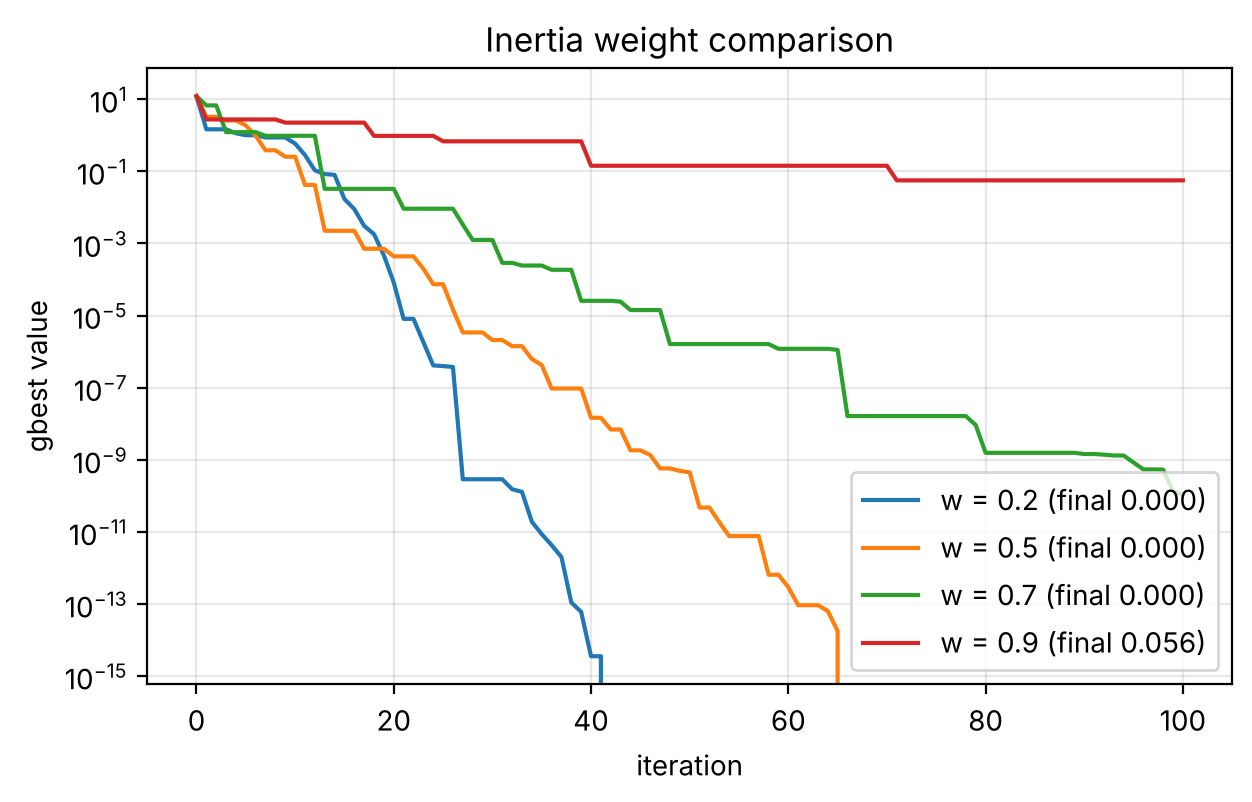

In [4]:
plt.figure(figsize=(7, 4))
for w in [0.2, 0.5, 0.7, 0.9]:
    np.random.seed(0)
    _, v, h, _ = pso(rastrigin, w=w)
    plt.plot(h, label=f"w = {w} (final {v:.3f})")
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("gbest value")
plt.legend(); plt.grid(alpha=0.3); plt.title("Inertia weight comparison"); plt.show()

## Conclusion
PSO located the region of the global minimum of the Rastrigin function. The swarm starts spread over the search space and gradually clusters around the best position. The inertia weight balances exploration (large w) and exploitation (small w).